# Model A vs Model B: comparison on a shared, unseen test set

**Goal:** compare the two trained models on reviews that **neither model saw during training**. No retraining is needed.

- **Model A:** Pre-LN encoder-only Transformer trained from scratch (~40.8M params). Trained on the full deduplicated Yelp dataset, minus its own 20k val + 40k test.
- **Model B:** `distilbert-base-uncased`, fine-tuned (~67M params). Trained on the team's balanced 150k sample (120k train / 15k val / 15k test).

**Evaluation set:** Model A's 40k held-out test set, **minus every review that appears in Model B's train or validation split**. Reviews are matched on normalized text (lowercase + collapsed whitespace), because Model A's cache has no `review_id` and Model A deduplicated by normalized text.

We report two views:
1. **Natural:** the remaining reviews with Yelp's real class distribution (~67% positive, ~10% neutral). This is the realistic deployment setting.
2. **Balanced:** a seeded subsample with an equal count per class, matching Model B's own test distribution.

Lead with **Macro-F1 + per-class F1**. Accuracy on the natural set favors Model A, because Model A was trained on that distribution and Model B on balanced data.

**Caveat for the report:** the two models differ in training data (≈6.9M imbalanced vs 120k balanced) *and* in architecture/pretraining. This compares two complete pipelines, not architecture alone.

### Runtime
Any Colab GPU works (T4 or A100); CPU works too, just slower. No training happens here.

### Required Drive files
- `MyDrive/yelp_model_a/checkpoints_v2/best_model.pt`
- `MyDrive/yelp_model_a/artifacts_v2/metrics.json` (for the tuned logit biases)
- `MyDrive/yelp_model_a/tokenized/{test_texts.jsonl, labels.npy, test_idx.npy}`
- `MyDrive/NLP_Task3/dataset/processed/yelp_{train,validation}_150k_seed42.csv.gz`
- `MyDrive/NLP_Task3/pretrained_model/distilbert_yelp_sentiment_clean/`

If `NLP_Task3` shows up under *Shared with me*, right-click it and choose **Organize → Add shortcut → My Drive** first.

## 1. Setup & paths

In [3]:
import os
from pathlib import Path

root = Path("/content/drive/MyDrive")
print("My Drive root:", sorted(os.listdir(root))[:50])

for name in ["yelp_model_a", "NLP_Task3"]:
    p = root / name
    print(f"\n{name} exists:", p.exists())
    if p.exists():
        for dirpath, dirnames, filenames in os.walk(p):
            depth = Path(dirpath).relative_to(p).parts
            if len(depth) > 2:
                continue
            print("  ", dirpath.replace(str(root) + "/", ""), "|", sorted(dirnames)[:10], sorted(filenames)[:10])

My Drive root: ['Colab Notebooks', 'NLP_Task3', 'processed', "vision agent usin voice (nelly's grad-project)"]

yelp_model_a exists: False

NLP_Task3 exists: True
   NLP_Task3 | ['NLP_Task3', 'pretrained_model', 'results', 'yelp_model_a'] []
   NLP_Task3/pretrained_model | [] []
   NLP_Task3/results | ['comparison'] []
   NLP_Task3/results/comparison | [] []


In [5]:
import json
import math
import os
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm

from google.colab import drive

drive.mount("/content/drive", force_remount=False)

MYDRIVE = Path("/content/drive/MyDrive")
MY_PROJECT = MYDRIVE / "NLP_Task3"  # your own folder that holds the two shortcuts

# ---- Model A (scratch) ----
A_ROOT = MY_PROJECT / "yelp_model_a"
A_CKPT = A_ROOT / "checkpoints_v2" / "best_model.pt"
A_METRICS = A_ROOT / "artifacts_v2" / "metrics.json"
A_TOKENIZED = A_ROOT / "tokenized"
A_TEST_TEXTS = A_TOKENIZED / "test_texts.jsonl"
A_LABELS = A_TOKENIZED / "labels.npy"
A_TEST_IDX = A_TOKENIZED / "test_idx.npy"

# ---- Model B (pretrained, team folder shortcut) ----
TEAM_ROOT = MY_PROJECT / "NLP_Task3"
B_MODEL_DIR = TEAM_ROOT / "pretrained_model" / "distilbert_yelp_sentiment_clean"
B_SPLIT_DIR = TEAM_ROOT / "dataset" / "processed"
B_TRAIN_CSV = B_SPLIT_DIR / "yelp_train_150k_seed42.csv.gz"
B_VAL_CSV = B_SPLIT_DIR / "yelp_validation_150k_seed42.csv.gz"
B_TEST_CSV = B_SPLIT_DIR / "yelp_test_150k_seed42.csv.gz"  # info only (overlap report)
B_MAX_LENGTH = 256

# ---- Outputs (your own folder, so no write-permission issues) ----
OUT_DIR = MY_PROJECT / "results" / "comparison"
OUT_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
LABEL_NAMES = ["negative", "neutral", "positive"]

required = {
    "Model A checkpoint": A_CKPT,
    "Model A metrics.json": A_METRICS,
    "Model A test texts": A_TEST_TEXTS,
    "Model A labels.npy": A_LABELS,
    "Model A test_idx.npy": A_TEST_IDX,
    "Model B model dir": B_MODEL_DIR,
    "Model B train split": B_TRAIN_CSV,
    "Model B validation split": B_VAL_CSV,
}
missing = [f"{name}: {path}" for name, path in required.items() if not path.exists()]
if missing:
    # Show what is actually inside the shortcuts to make path fixes easy.
    for shortcut in (A_ROOT, TEAM_ROOT):
        if shortcut.exists():
            print(f"\nContents of {shortcut}:")
            for child in sorted(shortcut.iterdir()):
                kids = sorted(c.name for c in child.iterdir())[:15] if child.is_dir() else []
                print(f"  {child.name}{'/' if child.is_dir() else ''} {kids if kids else ''}")
        else:
            print(f"\n{shortcut} does not exist")
    raise FileNotFoundError("Missing required files:\n  " + "\n  ".join(missing))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_BF16 = device.type == "cuda" and torch.cuda.is_bf16_supported()
USE_FP16 = device.type == "cuda" and not USE_BF16
AMP_DTYPE = torch.bfloat16 if USE_BF16 else (torch.float16 if USE_FP16 else None)
gpu_name = torch.cuda.get_device_name(0) if device.type == "cuda" else "cpu"
print(f"Device: {device} ({gpu_name}) | autocast dtype for batch eval: {AMP_DTYPE}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda (Tesla T4) | autocast dtype for batch eval: torch.bfloat16


## 2. Model A architecture (copied verbatim from the training notebook)

In [6]:
from dataclasses import dataclass

LABEL2ID: dict[str, int] = {
    "negative": 0,
    "neutral": 1,
    "positive": 2,
}

ID2LABEL: dict[int, str] = {
    0: "negative",
    1: "neutral",
    2: "positive",
}


@dataclass
class ModelAConfig:
    """Architecture hyperparameters for the scratch encoder-only Transformer."""

    vocab_size: int = 30522
    pad_token_id: int = 0
    d_model: int = 512
    num_layers: int = 8
    num_heads: int = 8
    d_ff: int = 2048
    max_seq_len: int = 256
    dropout: float = 0.10
    num_classes: int = 3
    head_tokens: int = 192
    tail_tokens: int = 64

    def __post_init__(self) -> None:
        # Token IDs are serialized to uint16 memmap storage, so vocab_size must fit in uint16.
        if self.vocab_size <= 0 or self.vocab_size > 65535:
            raise ValueError(f"vocab_size must be in [1, 65535], got {self.vocab_size}")
        if not (0 <= self.pad_token_id < self.vocab_size):
            raise ValueError(
                f"pad_token_id ({self.pad_token_id}) must be in [0, {self.vocab_size})"
            )
        if self.d_model <= 0 or self.num_heads <= 0 or self.d_model % self.num_heads != 0:
            raise ValueError(
                f"d_model ({self.d_model}) must be positive and divisible by num_heads ({self.num_heads})"
            )
        if self.num_layers <= 0 or self.d_ff <= 0 or self.num_classes <= 0:
            raise ValueError("num_layers, d_ff, and num_classes must be positive")
        if self.head_tokens < 0 or self.tail_tokens < 0:
            raise ValueError("head_tokens and tail_tokens must be non-negative")
        if self.head_tokens + self.tail_tokens != self.max_seq_len:
            raise ValueError(
                f"head_tokens ({self.head_tokens}) + tail_tokens ({self.tail_tokens}) "
                f"must equal max_seq_len ({self.max_seq_len})"
            )
        if not (0.0 <= self.dropout < 1.0):
            raise ValueError(f"dropout must be in [0.0, 1.0), got {self.dropout}")


@dataclass
class TrainingConfig:
    """Dataset, optimization, bucketing, and checkpointing hyperparameters."""

    seed: int = 42
    micro_batch_size: int = 256
    grad_accum_steps: int = 2
    epochs: int = 3
    peak_lr: float = 5e-4
    min_lr_ratio: float = 0.05
    warmup_ratio: float = 0.04
    weight_decay: float = 0.1
    label_smoothing: float = 0.1
    betas: tuple[float, float] = (0.9, 0.98)
    eps: float = 1e-8
    grad_clip_norm: float = 1.0
    bucket_multiple: int = 64
    mega_batch_mult: int = 50
    val_size: int = 20_000
    test_size: int = 40_000
    checkpoint_every_steps: int = 2000
    val_every_steps: int = 2000
    tokenizer_name: str = "bert-base-uncased"
    dataset_slug: str = "yelp-dataset/yelp-dataset"
    dataset_file: str = "yelp_academic_dataset_review.json"
    dataset_url: str = "https://www.kaggle.com/datasets/yelp-dataset/yelp-dataset"
    dataset_license: str = "Yelp Dataset Agreement (non-commercial academic/educational use)"

In [7]:
"""PyTorch encoder-only Transformer classifier built strictly from manual primitives."""

import math

import torch
import torch.nn as nn
import torch.nn.functional as F

try:
    from src.config import ModelAConfig
except ImportError:
    pass


class SinusoidalPositionalEncoding(nn.Module):
    """Fixed sinusoidal positional encoding added to scaled token embeddings."""

    def __init__(self, d_model: int, max_len: int, dropout: float) -> None:
        super().__init__()
        self.dropout = nn.Dropout(dropout)

        pe = torch.zeros(max_len, d_model, dtype=torch.float32)
        position = torch.arange(0, max_len, dtype=torch.float32).unsqueeze(1)
        div_term = torch.exp(
            torch.arange(0, d_model, 2, dtype=torch.float32) * (-math.log(10000.0) / d_model)
        )
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term[: d_model // 2])
        # Register as a non-trainable buffer with leading batch dim (1, max_len, d_model).
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Match input dtype so bf16/fp16 autocast activations are not silently promoted to fp32.
        x = x + self.pe[:, : x.size(1)].to(dtype=x.dtype)
        return self.dropout(x)


class ManualMultiHeadSelfAttention(nn.Module):
    """Manual multi-head self-attention with fp32 softmax masking for AMP stability."""

    def __init__(self, d_model: int, num_heads: int, dropout: float) -> None:
        super().__init__()
        if d_model % num_heads != 0:
            raise ValueError(f"d_model ({d_model}) must be divisible by num_heads ({num_heads})")
        self.d_model = d_model
        self.num_heads = num_heads
        self.d_k = d_model // num_heads

        self.w_q = nn.Linear(d_model, d_model, bias=True)
        self.w_k = nn.Linear(d_model, d_model, bias=True)
        self.w_v = nn.Linear(d_model, d_model, bias=True)
        self.w_o = nn.Linear(d_model, d_model, bias=True)
        self.attn_drop = nn.Dropout(dropout)

    def forward(
        self,
        x: torch.Tensor,
        key_padding_mask: torch.Tensor | None = None,
    ) -> torch.Tensor:
        bsz, seq_len, _ = x.shape

        # Project and reshape from (B, T, D) into (B, H, T, d_k).
        q = self.w_q(x).view(bsz, seq_len, self.num_heads, self.d_k).transpose(1, 2)
        k = self.w_k(x).view(bsz, seq_len, self.num_heads, self.d_k).transpose(1, 2)
        v = self.w_v(x).view(bsz, seq_len, self.num_heads, self.d_k).transpose(1, 2)

        scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(self.d_k)

        # Compute masked softmax in fp32 to prevent overflow/underflow under bf16/fp16 autocast.
        scores = scores.to(torch.float32)
        if key_padding_mask is not None:
            pad_positions = ~key_padding_mask.bool()
            scores = scores.masked_fill(pad_positions[:, None, None, :], float("-inf"))

        attn_probs = F.softmax(scores, dim=-1).to(v.dtype)
        attn_probs = self.attn_drop(attn_probs)

        out = torch.matmul(attn_probs, v)
        out = out.transpose(1, 2).contiguous().view(bsz, seq_len, self.d_model)
        return self.w_o(out)


class PositionWiseFeedForward(nn.Module):
    """Two-layer position-wise FFN with GELU activation."""

    def __init__(self, d_model: int, d_ff: int, dropout: float) -> None:
        super().__init__()
        self.fc1 = nn.Linear(d_model, d_ff)
        self.act = nn.GELU()
        self.drop = nn.Dropout(dropout)
        self.fc2 = nn.Linear(d_ff, d_model)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.fc2(self.drop(self.act(self.fc1(x))))


class PreLNEncoderBlock(nn.Module):
    """Pre-LayerNorm encoder block with residual self-attention and FFN sublayers."""

    def __init__(self, d_model: int, num_heads: int, d_ff: int, dropout: float) -> None:
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.attn = ManualMultiHeadSelfAttention(d_model, num_heads, dropout)
        self.drop1 = nn.Dropout(dropout)
        self.ln2 = nn.LayerNorm(d_model)
        self.ffn = PositionWiseFeedForward(d_model, d_ff, dropout)
        self.drop2 = nn.Dropout(dropout)

    def forward(
        self,
        x: torch.Tensor,
        key_padding_mask: torch.Tensor | None = None,
    ) -> torch.Tensor:
        x = x + self.drop1(self.attn(self.ln1(x), key_padding_mask))
        x = x + self.drop2(self.ffn(self.ln2(x)))
        return x


class ScratchTransformerClassifier(nn.Module):
    """Encoder-only Transformer classifier with masked mean pooling over token states."""

    def __init__(self, config: ModelAConfig) -> None:
        super().__init__()
        self.config = config
        self.d_model = config.d_model
        self.pad_token_id = config.pad_token_id

        self.token_emb = nn.Embedding(
            config.vocab_size,
            config.d_model,
            padding_idx=config.pad_token_id,
        )
        self.pos_enc = SinusoidalPositionalEncoding(
            config.d_model,
            config.max_seq_len,
            config.dropout,
        )
        self.layers = nn.ModuleList(
            [
                PreLNEncoderBlock(
                    config.d_model,
                    config.num_heads,
                    config.d_ff,
                    config.dropout,
                )
                for _ in range(config.num_layers)
            ]
        )
        self.final_ln = nn.LayerNorm(config.d_model)
        self.head_drop = nn.Dropout(config.dropout)
        self.classifier = nn.Linear(config.d_model, config.num_classes)

        self._init_weights()

    def _init_weights(self) -> None:
        for module in self.modules():
            if isinstance(module, nn.Linear):
                nn.init.normal_(module.weight, mean=0.0, std=0.02)
                if module.bias is not None:
                    nn.init.zeros_(module.bias)
            elif isinstance(module, nn.Embedding):
                nn.init.normal_(module.weight, mean=0.0, std=0.02)
                if module.padding_idx is not None:
                    with torch.no_grad():
                        module.weight[module.padding_idx].zero_()
            elif isinstance(module, nn.LayerNorm):
                nn.init.ones_(module.weight)
                nn.init.zeros_(module.bias)

        # Scale residual output projections by 1 / sqrt(2 * num_layers) to stabilize
        # variance growth across stacked Pre-LN residual additions.
        resid_std = 0.02 / math.sqrt(2 * self.config.num_layers)
        for layer in self.layers:
            nn.init.normal_(layer.attn.w_o.weight, mean=0.0, std=resid_std)
            nn.init.normal_(layer.ffn.fc2.weight, mean=0.0, std=resid_std)

    def forward(
        self,
        input_ids: torch.Tensor,
        attention_mask: torch.Tensor | None = None,
    ) -> torch.Tensor:
        mask = (input_ids != self.pad_token_id) if attention_mask is None else attention_mask.bool()

        # Scale embeddings by sqrt(d_model) so token magnitude balances unit sinusoidal PE.
        x = self.token_emb(input_ids) * math.sqrt(self.d_model)
        x = self.pos_enc(x)

        for layer in self.layers:
            x = layer(x, mask)

        x = self.final_ln(x)

        # Masked mean pooling averages only non-pad positions and clamps denom >= 1.0 for safety.
        mask_f = mask.unsqueeze(-1).type_as(x)
        pooled = (x * mask_f).sum(dim=1) / mask_f.sum(dim=1).clamp(min=1.0)
        return self.classifier(self.head_drop(pooled))

    def count_parameters(self) -> dict[str, int]:
        total = sum(p.numel() for p in self.parameters())
        trainable = sum(p.numel() for p in self.parameters() if p.requires_grad)
        embedding = sum(p.numel() for p in self.token_emb.parameters())
        return {
            "total": total,
            "trainable": trainable,
            "embedding": embedding,
            "non_embedding": total - embedding,
        }


def build_adamw_param_groups(model: nn.Module, weight_decay: float) -> list[dict]:
    """Decay 2D+ weight matrices; exempt biases, LayerNorm gains, and token embeddings."""
    decay_params: list[torch.nn.Parameter] = []
    no_decay_params: list[torch.nn.Parameter] = []

    for name, param in model.named_parameters():
        if not param.requires_grad:
            continue
        if param.ndim >= 2 and "token_emb" not in name:
            decay_params.append(param)
        else:
            no_decay_params.append(param)

    return [
        {"params": decay_params, "weight_decay": weight_decay},
        {"params": no_decay_params, "weight_decay": 0.0},
    ]

## 3. Core helpers (pure NumPy/pandas: slice building, metrics, bootstrap)

In [8]:
def normalize_for_dedup(text: str) -> str:
    """Same normalization Model A used for dedup: lowercase + collapse whitespace."""
    return " ".join(str(text).strip().lower().split())


def head_tail_truncate(token_ids, max_len=256, head_tokens=192, tail_tokens=64):
    if len(token_ids) <= max_len:
        return list(token_ids)
    head = token_ids[:head_tokens] if head_tokens > 0 else []
    tail = token_ids[-tail_tokens:] if tail_tokens > 0 else []
    return (head + tail)[:max_len]


def build_eval_slice(a_texts, a_labels, b_seen_texts, b_test_texts=(), seed=42):
    """Return (natural_positions, balanced_positions, report).

    natural_positions: positions in Model A's test set whose normalized text is NOT in
    Model B's train/val. balanced_positions: a seeded equal-per-class subsample of those.
    """
    a_norm = np.array([normalize_for_dedup(t) for t in a_texts], dtype=object)
    b_seen = {normalize_for_dedup(t) for t in b_seen_texts}
    b_test = {normalize_for_dedup(t) for t in b_test_texts}

    in_b_seen = np.fromiter((t in b_seen for t in a_norm), dtype=bool, count=len(a_norm))
    in_b_test = np.fromiter((t in b_test for t in a_norm), dtype=bool, count=len(a_norm))
    natural = np.flatnonzero(~in_b_seen)

    labels = np.asarray(a_labels, dtype=np.int64)
    nat_labels = labels[natural]
    counts = np.bincount(nat_labels, minlength=3)
    per_class = int(counts.min())
    rng = np.random.default_rng(seed)
    balanced = np.sort(np.concatenate([
        rng.choice(natural[nat_labels == c], size=per_class, replace=False) for c in range(3)
    ]))

    report = {
        "model_a_test_size": int(len(a_texts)),
        "removed_seen_by_model_b": int(in_b_seen.sum()),
        "also_in_model_b_test_kept": int((in_b_test & ~in_b_seen).sum()),
        "natural_size": int(len(natural)),
        "natural_class_counts": {LABEL_NAMES[c]: int(counts[c]) for c in range(3)},
        "balanced_per_class": per_class,
        "balanced_size": int(len(balanced)),
        "match_key": "normalized text (lowercase + collapsed whitespace)",
        "seed": seed,
    }
    return natural, balanced, report


def confusion(y_true, y_pred, k=3):
    return np.bincount(np.asarray(y_true) * k + np.asarray(y_pred), minlength=k * k).reshape(k, k)


def metrics_from_confusion(cm):
    cm = np.asarray(cm, dtype=np.float64)
    tp = np.diag(cm)
    support = cm.sum(axis=1)
    pred_count = cm.sum(axis=0)
    precision = np.divide(tp, pred_count, out=np.zeros_like(tp), where=pred_count > 0)
    recall = np.divide(tp, support, out=np.zeros_like(tp), where=support > 0)
    denom = precision + recall
    f1 = np.divide(2 * precision * recall, denom, out=np.zeros_like(tp), where=denom > 0)
    total = cm.sum()
    weights = support / total if total > 0 else np.zeros_like(support)
    return {
        "accuracy": float(tp.sum() / total) if total > 0 else 0.0,
        "precision_macro": float(precision.mean()),
        "recall_macro": float(recall.mean()),
        "f1_macro": float(f1.mean()),
        "f1_weighted": float((f1 * weights).sum()),
        "per_class": {
            LABEL_NAMES[i]: {
                "precision": float(precision[i]),
                "recall": float(recall[i]),
                "f1": float(f1[i]),
                "support": int(support[i]),
            }
            for i in range(len(LABEL_NAMES))
        },
        "confusion_matrix": {"labels": LABEL_NAMES, "matrix": cm.astype(int).tolist()},
    }


def compute_metrics(y_true, y_pred):
    return metrics_from_confusion(confusion(y_true, y_pred))


def paired_bootstrap_macro_f1(y_true, pred_a, pred_b, n_boot=1000, seed=42):
    """Paired bootstrap over reviews: CI for macro-F1(A) - macro-F1(B) and P(A > B)."""
    y_true = np.asarray(y_true)
    pred_a = np.asarray(pred_a)
    pred_b = np.asarray(pred_b)
    n = len(y_true)
    rng = np.random.default_rng(seed)
    diffs = np.empty(n_boot)
    for i in range(n_boot):
        idx = rng.integers(0, n, size=n)
        f1_a = metrics_from_confusion(confusion(y_true[idx], pred_a[idx]))["f1_macro"]
        f1_b = metrics_from_confusion(confusion(y_true[idx], pred_b[idx]))["f1_macro"]
        diffs[i] = f1_a - f1_b
    observed = (
        compute_metrics(y_true, pred_a)["f1_macro"] - compute_metrics(y_true, pred_b)["f1_macro"]
    )
    return {
        "macro_f1_diff_a_minus_b": float(observed),
        "ci95_low": float(np.percentile(diffs, 2.5)),
        "ci95_high": float(np.percentile(diffs, 97.5)),
        "p_a_better": float((diffs > 0).mean()),
        "n_boot": n_boot,
    }

## 4. Build the shared unseen evaluation slice

In [9]:
with A_TEST_TEXTS.open("r", encoding="utf-8") as f:
    a_test_texts = [json.loads(line)["text"] for line in f]
a_test_idx = np.load(A_TEST_IDX)
a_test_labels = np.load(A_LABELS, mmap_mode="r")[a_test_idx].astype(np.int64)
assert len(a_test_texts) == len(a_test_labels), "test_texts.jsonl is out of sync with test_idx.npy"

b_train = pd.read_csv(B_TRAIN_CSV)
b_val = pd.read_csv(B_VAL_CSV)
b_seen_texts = pd.concat([b_train["text"], b_val["text"]], ignore_index=True).astype(str).tolist()
b_test_texts = pd.read_csv(B_TEST_CSV)["text"].astype(str).tolist() if B_TEST_CSV.exists() else []

t0 = time.perf_counter()
natural_pos, balanced_pos, slice_report = build_eval_slice(
    a_test_texts, a_test_labels, b_seen_texts, b_test_texts, seed=SEED
)
print(f"Built eval slice in {time.perf_counter() - t0:.1f}s")
print(json.dumps(slice_report, indent=2))

np.save(OUT_DIR / "eval_natural_positions.npy", natural_pos)
np.save(OUT_DIR / "eval_balanced_positions.npy", balanced_pos)
(OUT_DIR / "eval_slice_report.json").write_text(json.dumps(slice_report, indent=2), encoding="utf-8")

eval_texts = [a_test_texts[i] for i in natural_pos]
eval_labels = a_test_labels[natural_pos]
# Position of each balanced review inside the natural slice (for subsetting predictions).
balanced_in_natural = np.searchsorted(natural_pos, balanced_pos)
assert np.array_equal(natural_pos[balanced_in_natural], balanced_pos)

Built eval slice in 1.7s
{
  "model_a_test_size": 40000,
  "removed_seen_by_model_b": 781,
  "also_in_model_b_test_kept": 90,
  "natural_size": 39219,
  "natural_class_counts": {
    "negative": 8964,
    "neutral": 3734,
    "positive": 26521
  },
  "balanced_per_class": 3734,
  "balanced_size": 11202,
  "match_key": "normalized text (lowercase + collapsed whitespace)",
  "seed": 42
}


## 5. Load both models

In [12]:
OLD_B_DIR = TEAM_ROOT / "pretrained_model" / "distilbert_yelp_sentiment"
for f in sorted(OLD_B_DIR.iterdir()):
    print(f"  {f.name:30s} {f.stat().st_size / 1e6:8.1f} MB")

  config.json                         0.0 MB
  model.safetensors                 267.8 MB
  special_tokens_map.json             0.0 MB
  tokenizer.json                      0.7 MB
  tokenizer_config.json               0.0 MB
  vocab.txt                           0.2 MB


In [14]:
from transformers import AutoModelForSequenceClassification, AutoTokenizer

# ---- Model A ----
a_ckpt = torch.load(A_CKPT, map_location="cpu", weights_only=False)
a_cfg = ModelAConfig(**a_ckpt["model_cfg"])
model_a = ScratchTransformerClassifier(a_cfg)
a_state = {
    (k[len("_orig_mod."):] if k.startswith("_orig_mod.") else k): v
    for k, v in a_ckpt["model_state_dict"].items()
}
model_a.load_state_dict(a_state)
model_a.to(device).eval()
tok_a = AutoTokenizer.from_pretrained("bert-base-uncased")

a_metrics_json = json.loads(A_METRICS.read_text(encoding="utf-8"))
a_biases = np.asarray(
    a_metrics_json.get("logit_bias_tuning", {}).get("biases", [0.0, 0.0, 0.0]), dtype=np.float64
)
print("Model A params:", sum(p.numel() for p in model_a.parameters()), "| logit biases:", a_biases.tolist())

# ---- Model B ----
# The "_clean" folder has no model.safetensors, so we use the first DistilBERT run,
# whose folder is complete (weights + config + tokenizer).
B_MODEL_DIR = TEAM_ROOT / "pretrained_model" / "distilbert_yelp_sentiment"
assert (B_MODEL_DIR / "model.safetensors").exists(), f"No weights in {B_MODEL_DIR}"

tok_b = AutoTokenizer.from_pretrained(B_MODEL_DIR)
model_b = AutoModelForSequenceClassification.from_pretrained(B_MODEL_DIR).to(device).eval()
assert model_b.config.num_labels == 3, f"Model B has {model_b.config.num_labels} labels, expected 3"
print("Model B dir:", B_MODEL_DIR)
print("Model B params:", sum(p.numel() for p in model_b.parameters()), "| id2label:", model_b.config.id2label)

Model A params: 40848899 | logit biases: [0.38958333333333284, 0.8968749999999999, 0.0]


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Model B dir: /content/drive/MyDrive/NLP_Task3/NLP_Task3/pretrained_model/distilbert_yelp_sentiment
Model B params: 66955779 | id2label: {0: 'negative', 1: 'neutral', 2: 'positive'}


## 6. Batched inference on the full natural slice

In [15]:
def _autocast():
    if AMP_DTYPE is None:
        return torch.autocast("cpu", enabled=False)
    return torch.autocast("cuda", dtype=AMP_DTYPE)


@torch.inference_mode()
def logits_model_a(texts, batch_size=256):
    ids_all = [
        head_tail_truncate(ids, a_cfg.max_seq_len, a_cfg.head_tokens, a_cfg.tail_tokens)
        for ids in tok_a(texts, add_special_tokens=True, truncation=False, padding=False)["input_ids"]
    ]
    order = np.argsort([len(x) for x in ids_all], kind="mergesort")  # length-sorted batches
    out = np.zeros((len(texts), 3), dtype=np.float32)
    for s in tqdm(range(0, len(order), batch_size), desc="Model A"):
        batch_idx = order[s:s + batch_size]
        max_len = max(len(ids_all[i]) for i in batch_idx)
        ids = torch.full((len(batch_idx), max_len), a_cfg.pad_token_id, dtype=torch.long)
        for row, i in enumerate(batch_idx):
            ids[row, :len(ids_all[i])] = torch.tensor(ids_all[i], dtype=torch.long)
        ids = ids.to(device)
        with _autocast():
            logits = model_a(ids, ids != a_cfg.pad_token_id)
        out[batch_idx] = logits.float().cpu().numpy()
    return out


@torch.inference_mode()
def logits_model_b(texts, batch_size=128):
    lengths = [len(t) for t in texts]
    order = np.argsort(lengths, kind="mergesort")
    out = np.zeros((len(texts), 3), dtype=np.float32)
    for s in tqdm(range(0, len(order), batch_size), desc="Model B"):
        batch_idx = order[s:s + batch_size]
        enc = tok_b(
            [texts[i] for i in batch_idx],
            truncation=True,
            max_length=B_MAX_LENGTH,
            padding=True,
            return_tensors="pt",
        ).to(device)
        with _autocast():
            logits = model_b(**enc).logits
        out[batch_idx] = logits.float().cpu().numpy()
    return out


t0 = time.perf_counter()
logits_a = logits_model_a(eval_texts)
print(f"Model A batch inference: {time.perf_counter() - t0:.1f}s")
t0 = time.perf_counter()
logits_b = logits_model_b(eval_texts)
print(f"Model B batch inference: {time.perf_counter() - t0:.1f}s")

pred_a_raw = logits_a.argmax(-1)
pred_a_adj = (logits_a + a_biases).argmax(-1)
pred_b = logits_b.argmax(-1)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (588 > 512). Running this sequence through the model will result in indexing errors


Model A:   0%|          | 0/154 [00:00<?, ?it/s]

Model A batch inference: 119.6s


Model B:   0%|          | 0/307 [00:00<?, ?it/s]

Model B batch inference: 235.2s


## 7. Metrics: natural & balanced views, with a paired bootstrap

In [16]:
def eval_view(view_positions_in_natural):
    y = eval_labels[view_positions_in_natural]
    return {
        "size": int(len(y)),
        "model_a_raw": compute_metrics(y, pred_a_raw[view_positions_in_natural]),
        "model_a_logit_adjusted": compute_metrics(y, pred_a_adj[view_positions_in_natural]),
        "model_b": compute_metrics(y, pred_b[view_positions_in_natural]),
        "bootstrap_a_adjusted_vs_b": paired_bootstrap_macro_f1(
            y, pred_a_adj[view_positions_in_natural], pred_b[view_positions_in_natural], seed=SEED
        ),
        "agreement_rate_a_adjusted_vs_b": float(
            (pred_a_adj[view_positions_in_natural] == pred_b[view_positions_in_natural]).mean()
        ),
    }


all_natural = np.arange(len(natural_pos))
views = {
    "natural": eval_view(all_natural),
    "balanced": eval_view(balanced_in_natural),
}

rows = []
for view_name, v in views.items():
    for key, label in [
        ("model_a_raw", "Model A (raw)"),
        ("model_a_logit_adjusted", "Model A (logit-adjusted)"),
        ("model_b", "Model B (DistilBERT)"),
    ]:
        m = v[key]
        rows.append({
            "view": view_name,
            "model": label,
            "n": v["size"],
            "accuracy": round(m["accuracy"], 4),
            "macro_f1": round(m["f1_macro"], 4),
            "weighted_f1": round(m["f1_weighted"], 4),
            "f1_negative": round(m["per_class"]["negative"]["f1"], 4),
            "f1_neutral": round(m["per_class"]["neutral"]["f1"], 4),
            "f1_positive": round(m["per_class"]["positive"]["f1"], 4),
        })
summary_df = pd.DataFrame(rows)
display(summary_df)
for view_name, v in views.items():
    b = v["bootstrap_a_adjusted_vs_b"]
    print(
        f"[{view_name}] Macro-F1 (A_adj - B) = {b['macro_f1_diff_a_minus_b']:+.4f} "
        f"(95% CI {b['ci95_low']:+.4f} .. {b['ci95_high']:+.4f}) | agreement {v['agreement_rate_a_adjusted_vs_b']:.3f}"
    )
summary_df.to_csv(OUT_DIR / "comparison_summary.csv", index=False)

,view,model,n,accuracy,macro_f1,weighted_f1,f1_negative,f1_neutral,f1_positive
0,natural,Model A (raw),39219,0.8984,0.7716,0.8917,0.8869,0.4760,0.9518
1,natural,Model A (logit-adjusted),39219,0.8888,0.7890,0.8933,0.8822,0.5378,0.9471
2,natural,Model B (DistilBERT),39219,0.8713,0.7865,0.8860,0.8849,0.5394,0.9352
3,balanced,Model A (raw),11202,0.7575,0.7332,0.7332,0.8413,0.5414,0.8170
4,balanced,Model A (logit-adjusted),11202,0.8033,0.7966,0.7966,0.8495,0.6837,0.8565
5,balanced,Model B (DistilBERT),11202,0.8367,0.8365,0.8365,0.8557,0.7595,0.8942


[natural] Macro-F1 (A_adj - B) = +0.0025 (95% CI -0.0024 .. +0.0077) | agreement 0.899
[balanced] Macro-F1 (A_adj - B) = -0.0399 (95% CI -0.0474 .. -0.0330) | agreement 0.858


## 8. Single-review latency: same machine, same protocol for both models

In [17]:
@torch.inference_mode()
def measure_latency(predict_one, texts, warmup=5, steps=50):
    """bs=1, fp32, tokenization + forward, CUDA-synchronized (same protocol as the Model B notebook)."""
    for t in texts[:warmup]:
        predict_one(t)
    lat = []
    for t in texts[warmup:warmup + steps]:
        if device.type == "cuda":
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        predict_one(t)
        if device.type == "cuda":
            torch.cuda.synchronize()
        lat.append((time.perf_counter() - t0) * 1000.0)
    arr = np.asarray(lat)
    return {
        "mean_ms": float(arr.mean()),
        "median_ms": float(np.median(arr)),
        "p95_ms": float(np.percentile(arr, 95)),
        "n": int(len(arr)),
    }


def predict_one_a(text):
    ids = head_tail_truncate(
        tok_a(text, add_special_tokens=True, truncation=False, padding=False)["input_ids"],
        a_cfg.max_seq_len, a_cfg.head_tokens, a_cfg.tail_tokens,
    )
    x = torch.tensor([ids], dtype=torch.long, device=device)
    return model_a(x, x != a_cfg.pad_token_id)


def predict_one_b(text):
    enc = tok_b(text, truncation=True, max_length=B_MAX_LENGTH, return_tensors="pt").to(device)
    return model_b(**enc).logits


latency_texts = [eval_texts[i] for i in balanced_in_natural[:55]]
latency = {
    "device": str(device),
    "gpu_name": gpu_name,
    "protocol": "bs=1, fp32, tokenization+forward, 5 warm-up + 50 timed, CUDA-synchronized",
    "model_a": measure_latency(predict_one_a, latency_texts),
    "model_b": measure_latency(predict_one_b, latency_texts),
}
print(json.dumps(latency, indent=2))

{
  "device": "cuda",
  "gpu_name": "Tesla T4",
  "protocol": "bs=1, fp32, tokenization+forward, 5 warm-up + 50 timed, CUDA-synchronized",
  "model_a": {
    "mean_ms": 7.234642340004029,
    "median_ms": 6.71953350001786,
    "p95_ms": 9.290666350011632,
    "n": 50
  },
  "model_b": {
    "mean_ms": 6.302470500013442,
    "median_ms": 6.1877040001263595,
    "p95_ms": 8.291567049911919,
    "n": 50
  }
}


## 9. Save artifacts (JSON for the app, predictions, plots, disagreement samples)

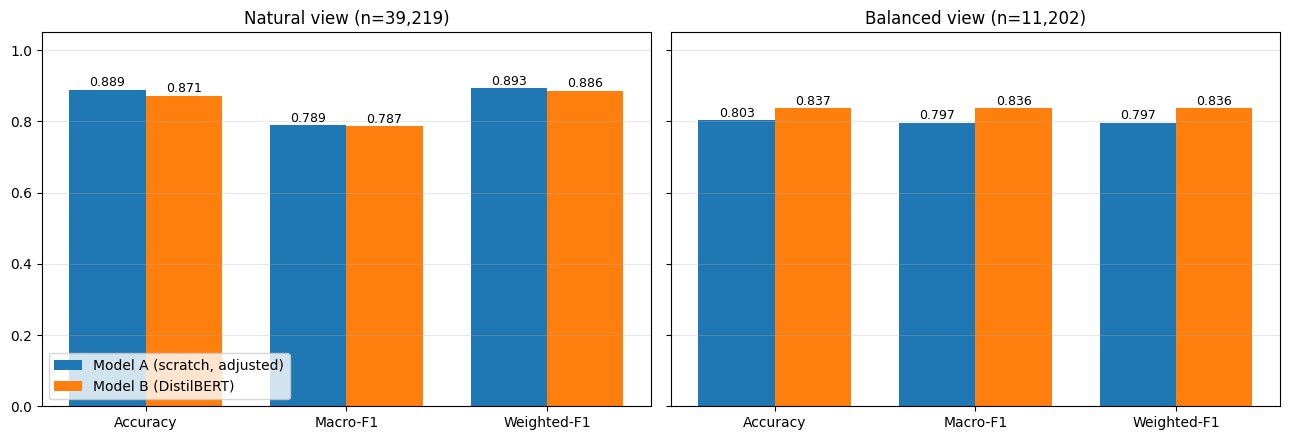

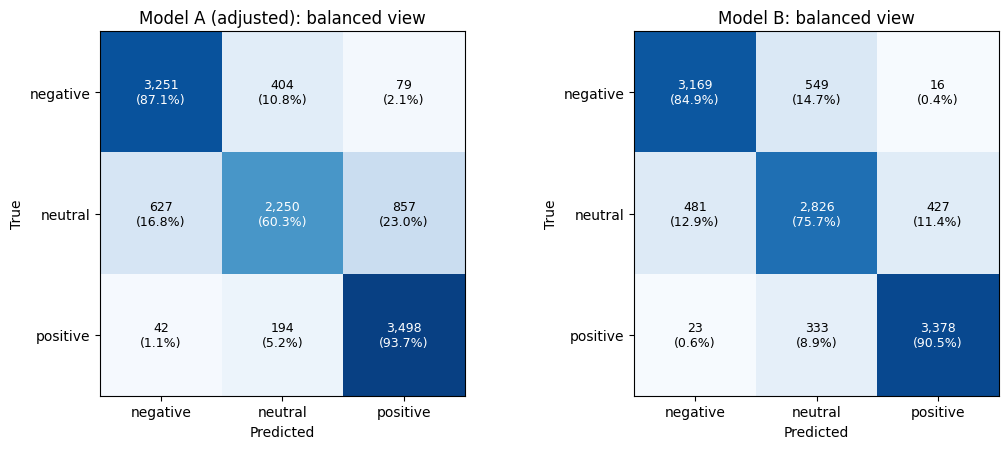

Saved to /content/drive/MyDrive/NLP_Task3/results/comparison:
   comparison_confusion_matrices.png
   comparison_metrics.png
   comparison_results.json
   comparison_summary.csv
   comparison_test_predictions.csv.gz
   disagreements_sample_PRIVATE.csv
   eval_balanced_positions.npy
   eval_natural_positions.npy
   eval_slice_report.json


In [18]:
import matplotlib.pyplot as plt

comparison = {
    "description": (
        "Model A's held-out test set minus reviews present in Model B's train/validation "
        "splits (matched on normalized text). Neither model saw these reviews during training."
    ),
    "caveat": (
        "Models differ in training data (Model A: ~6.9M imbalanced Yelp reviews; Model B: 120k "
        "balanced) as well as architecture/pretraining; this compares full pipelines."
    ),
    "eval_slice": slice_report,
    "models": {
        "model_a": {
            "name": "Model A: Scratch Pre-LN Transformer",
            "parameters": int(sum(p.numel() for p in model_a.parameters())),
            "tokenizer": "bert-base-uncased",
            "truncation": f"head+tail {a_cfg.head_tokens}+{a_cfg.tail_tokens} (max {a_cfg.max_seq_len})",
            "logit_biases": a_biases.tolist(),
            "own_test_metrics": {
                "test_raw": a_metrics_json.get("test_raw", {}),
                "test_logit_adjusted": a_metrics_json.get("test_logit_adjusted", {}),
            },
        },
        "model_b": {
            "name": "Model B: DistilBERT (fine-tuned)",
            "parameters": int(sum(p.numel() for p in model_b.parameters())),
            "tokenizer": "distilbert-base-uncased",
            "truncation": f"right truncation (max {B_MAX_LENGTH})",
        },
    },
    "views": views,
    "latency_same_machine": latency,
}
(OUT_DIR / "comparison_results.json").write_text(json.dumps(comparison, indent=2), encoding="utf-8")

# Per-review predictions (no text, safe to share; still keep large files out of git).
def _softmax(z):
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

probs_a = _softmax(logits_a + a_biases)
probs_b = _softmax(logits_b)
pred_df = pd.DataFrame({
    "model_a_test_position": natural_pos,
    "in_balanced_view": np.isin(natural_pos, balanced_pos),
    "label": eval_labels,
    "pred_a_raw": pred_a_raw,
    "pred_a_adjusted": pred_a_adj,
    "pred_b": pred_b,
    **{f"prob_a_{n}": probs_a[:, i] for i, n in enumerate(LABEL_NAMES)},
    **{f"prob_b_{n}": probs_b[:, i] for i, n in enumerate(LABEL_NAMES)},
})
pred_df.to_csv(OUT_DIR / "comparison_test_predictions.csv.gz", index=False, compression="gzip")

# Disagreement samples WITH review text: keep in Drive only, do not commit to the public repo.
disagree = np.flatnonzero(pred_a_adj != pred_b)
rng = np.random.default_rng(SEED)
sample = rng.choice(disagree, size=min(50, len(disagree)), replace=False)
pd.DataFrame({
    "text": [eval_texts[i] for i in sample],
    "label": [LABEL_NAMES[eval_labels[i]] for i in sample],
    "model_a": [LABEL_NAMES[pred_a_adj[i]] for i in sample],
    "model_b": [LABEL_NAMES[pred_b[i]] for i in sample],
    "prob_a": probs_a[sample].max(axis=1).round(4),
    "prob_b": probs_b[sample].max(axis=1).round(4),
}).to_csv(OUT_DIR / "disagreements_sample_PRIVATE.csv", index=False)

# Plot 1: grouped bars per view
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
metric_keys = [("accuracy", "Accuracy"), ("f1_macro", "Macro-F1"), ("f1_weighted", "Weighted-F1")]
for ax, (view_name, v) in zip(axes, views.items()):
    x = np.arange(len(metric_keys))
    w = 0.38
    va = [v["model_a_logit_adjusted"][k] for k, _ in metric_keys]
    vb = [v["model_b"][k] for k, _ in metric_keys]
    ax.bar(x - w / 2, va, w, label="Model A (scratch, adjusted)")
    ax.bar(x + w / 2, vb, w, label="Model B (DistilBERT)")
    for xi, (a_val, b_val) in enumerate(zip(va, vb)):
        ax.text(xi - w / 2, a_val + 0.01, f"{a_val:.3f}", ha="center", fontsize=9)
        ax.text(xi + w / 2, b_val + 0.01, f"{b_val:.3f}", ha="center", fontsize=9)
    ax.set_xticks(x)
    ax.set_xticklabels([n for _, n in metric_keys])
    ax.set_ylim(0, 1.05)
    ax.set_title(f"{view_name.capitalize()} view (n={v['size']:,})")
    ax.grid(axis="y", alpha=0.3)
axes[0].legend(loc="lower left")
fig.tight_layout()
fig.savefig(OUT_DIR / "comparison_metrics.png", dpi=150, bbox_inches="tight")
plt.show()

# Plot 2: confusion matrices (balanced view), row-normalized
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, (key, title) in zip(axes, [("model_a_logit_adjusted", "Model A (adjusted)"), ("model_b", "Model B")]):
    cm = np.asarray(views["balanced"][key]["confusion_matrix"]["matrix"], dtype=float)
    norm = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{int(cm[i, j]):,}\n({norm[i, j] * 100:.1f}%)", ha="center", va="center",
                    color="white" if norm[i, j] > 0.5 else "black", fontsize=9)
    ax.set_xticks(range(3))
    ax.set_yticks(range(3))
    ax.set_xticklabels(LABEL_NAMES)
    ax.set_yticklabels(LABEL_NAMES)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(f"{title}: balanced view")
fig.tight_layout()
fig.savefig(OUT_DIR / "comparison_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Saved to {OUT_DIR}:")
for p in sorted(OUT_DIR.iterdir()):
    print("  ", p.name)